# PhishGuard-AI: Model Evaluation

Final comparison of all trained models on the held-out test set.

## Imports and Settings

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import json
import time
import joblib
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, StratifiedGroupKFold, cross_val_score, cross_val_predict, learning_curve
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
import optuna

RANDOM_STATE = 42
N_SPLITS = 5
OPTUNA_TRIALS = 30
TARGET = "target"
LABEL_NAMES = ["Legitimate", "Phishing"]

pd.set_option("display.max_columns", 100)

## Project Paths

In [2]:
def find_repo_root():
    curr = Path.cwd().resolve()
    for p in [curr, *curr.parents]:
        if (p / "data" / "processed").exists():
            return p
    fallback = Path(r"C:\Users\Loq\Downloads\repo\PhishGuard-AI")
    if (fallback / "data" / "processed").exists():
        return fallback
    return curr

PROJECT_ROOT = find_repo_root()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RF_DIR = MODEL_DIR / "random_forest"
XGB_DIR = MODEL_DIR / "xgboost"
LGBM_DIR = MODEL_DIR / "lgbm"
CAT_DIR = MODEL_DIR /  "catboost"
DT_DIR = MODEL_DIR / "decision_tree"
SVM_DIR = MODEL_DIR / "svm"

print("Project root:", PROJECT_ROOT.resolve())
print("Data folder :", DATA_DIR.resolve())
print("Model folder:", MODEL_DIR.resolve())

Project root: C:\Users\LENOVO\OneDrive\Desktop\new\PhishGuard-AI
Data folder : C:\Users\LENOVO\OneDrive\Desktop\new\PhishGuard-AI\data\processed
Model folder: C:\Users\LENOVO\OneDrive\Desktop\new\PhishGuard-AI\models


## Load Data

Loads the PCA train/test splits and verifies both have identical feature columns.

In [3]:
final_csv = DATA_DIR / "final_dataset.csv"
train_pca_csv = DATA_DIR / "preprocessed_train_pca.csv"
test_pca_csv = DATA_DIR / "preprocessed_test_pca.csv"

if train_pca_csv.exists() and test_pca_csv.exists():
    print(f"Loading final dataset PCA splits from {DATA_DIR.resolve()}...")
    train_df = pd.read_csv(train_pca_csv)
    test_df = pd.read_csv(test_pca_csv)

elif Path("preprocessed_train_pca.csv").exists():
    print("Loading final dataset PCA splits from current folder...")
    train_df = pd.read_csv("preprocessed_train_pca.csv")
    test_df = pd.read_csv("preprocessed_test_pca.csv")

elif final_csv.exists():
    print(f"Loading directly from {final_csv.resolve()} and transforming via PCA...")
    df_raw = pd.read_csv(final_csv)
    df_work = df_raw[df_raw.get("is_benchmark_heldout", 0) == 0].copy().reset_index(drop=True)
    df_work["target"] = df_work["is_phishing"].astype(int)
    feature_cols = [
        'entropy', 'url_length', 'num_www', 'ratio_digits_url', 'num_subdomains',
        'length_hostname', 'random_domain', 'num_dots', 'num_hyphens', 'ratio_digits_host',
        'prefix_suffix', 'num_question_mark', 'num_eq', 'domain_age', 'dns_resolvable',
        'num_ips', 'ttl', 'num_name_servers', 'domain_age_unknown'
    ]
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    tr_idx, te_idx = next(sgkf.split(df_work, df_work["target"], groups=df_work["registered_domain"]))
    tr_raw, te_raw = df_work.iloc[tr_idx], df_work.iloc[te_idx]
    scaler = StandardScaler()
    pca = PCA(n_components=15, random_state=42)
    tr_pca = pca.fit_transform(scaler.fit_transform(tr_raw[feature_cols]))
    te_pca = pca.transform(scaler.transform(te_raw[feature_cols]))
    pca_cols = [f"PC{i+1:02d}" for i in range(15)]
    train_df = pd.DataFrame(tr_pca, columns=pca_cols)
    train_df["target"] = tr_raw["target"].values
    test_df = pd.DataFrame(te_pca, columns=pca_cols)
    test_df["target"] = te_raw["target"].values
    
else:
    raise FileNotFoundError(f"Cannot find dataset splits or final_dataset.csv in {DATA_DIR}")

if train_df.empty or test_df.empty:
    raise ValueError("Training and test CSV files must not be empty.")

for name, df in [("training", train_df), ("test", test_df)]:
    if TARGET not in df.columns:
        raise ValueError(f"The {name} dataset is missing the target column '{TARGET}'.")
    if df.columns.duplicated().any():
        raise ValueError(f"The {name} dataset contains duplicate column names.")

x_train = train_df.drop(columns=TARGET).copy()
y_train = train_df[TARGET].copy()
x_test = test_df.drop(columns=TARGET).copy()
y_test = test_df[TARGET].copy()
missing_in_test = [c for c in x_train.columns if c not in x_test.columns]
extra_in_test = [c for c in x_test.columns if c not in x_train.columns]

if missing_in_test or extra_in_test:
    raise ValueError(
        f"Feature mismatch. Missing in test: {missing_in_test}. Extra in test: {extra_in_test}"
    )

x_test = x_test[x_train.columns]

if list(x_train.columns) != list(x_test.columns):
    raise ValueError("Training and test features must have the same columns in the same order.")

print(f"Features verified: {x_train.shape[1]} identical columns in the same order.")

if y_train.value_counts().min() < N_SPLITS:
    raise ValueError(f"Each training class needs at least {N_SPLITS} rows for CV.")

display(pd.DataFrame({
    "Training count": y_train.value_counts().reindex([0, 1]),
    "Training %": (y_train.value_counts(normalize=True).reindex([0, 1]) * 100).round(2),
    "Test count": y_test.value_counts().reindex([0, 1], fill_value=0),
    "Test %": (y_test.value_counts(normalize=True).reindex([0, 1]) * 100).round(2)
}).rename(index={0: "Legitimate", 1: "Phishing"}))

Loading final dataset PCA splits from C:\Users\LENOVO\OneDrive\Desktop\new\PhishGuard-AI\data\processed...
Features verified: 25 identical columns in the same order.


,Training count,Training %,Test count,Test %
target,,,,
Legitimate,55036,65.85,13759,65.85
Phishing,28543,34.15,7136,34.15


## Load Models

Each model file is validated before loading.

In [4]:
rf_path = RF_DIR / "random_forest.joblib"

if not rf_path.is_file():
    raise FileNotFoundError(f"Model was not loaded: {rf_path}")

random_forest = joblib.load(rf_path)

In [5]:
lgbm_path = LGBM_DIR / "phishguard_lgbm.pkl"

if not lgbm_path.is_file():
    raise FileNotFoundError(f"Model was not loaded: {lgbm_path}")

lgbm_model = joblib.load(lgbm_path)

In [6]:
cat_path = CAT_DIR / "cat_boost.joblib"

if not cat_path.is_file():
    raise FileNotFoundError(f"Model was not loaded: {cat_path}")

cat_model = joblib.load(cat_path)

### Logistic Regression, XGBoost and XGBoost + LR

`chosen_threshold` is read from `xgboost_info.json` (saved at training time) and is applied **only** to the XGBoost + LR booster. All other models use their default 0.5 cutoff. The threshold must be selected on training or validation data (e.g., CV), never on the test labels, so the test set stays an unbiased final check.

In [7]:
lr_path = XGB_DIR / "lr_model.joblib"

if not lr_path.is_file():
    raise FileNotFoundError(f"Model was not loaded: {lr_path}")

final_lr = joblib.load(lr_path)


xgb_path = XGB_DIR / "lr_xgb_booster.json"

if not xgb_path.is_file():
    raise FileNotFoundError(f"Model was not loaded: {xgb_path}")

final_booster = xgb.Booster()
final_booster.load_model(xgb_path)

tuned_xgb_path = XGB_DIR / "tuned_xgb.json"

if not tuned_xgb_path.is_file():
    raise FileNotFoundError(f"Model was not loaded: {tuned_xgb_path}")

final_xgb = xgb.XGBClassifier()
final_xgb.load_model(tuned_xgb_path)

info_path = XGB_DIR / "xgboost_info.json"

if not info_path.is_file():
    raise FileNotFoundError(f"Threshold file was not loaded: {info_path}")

with open(info_path, "r") as f:
    info = json.load(f)

if "threshold" not in info:
    raise KeyError(f"'threshold' is missing from {info_path}")

chosen_threshold = float(info["threshold"])

if not 0 < chosen_threshold < 1:
    raise ValueError(f"Threshold must be between 0 and 1, got {chosen_threshold}")

print("Loaded threshold:", chosen_threshold)

Loaded threshold: 0.45


In [8]:
dt_path = DT_DIR / "decision_tree_pca_model.joblib"

if not dt_path.is_file():
    raise FileNotFoundError(f"Model was not loaded: {dt_path}")

decision_tree = joblib.load(dt_path)

In [9]:
svm_path = SVM_DIR / "svm.joblib"

if not svm_path.is_file():
    raise FileNotFoundError(f"Model was not loaded: {svm_path}")

svm = joblib.load(svm_path)

## Evaluate Models

Predicts on the test set and collects metrics, ROC/PR data, inference time and model size for every model. Inference time is a single run, so use it only for relative comparison.

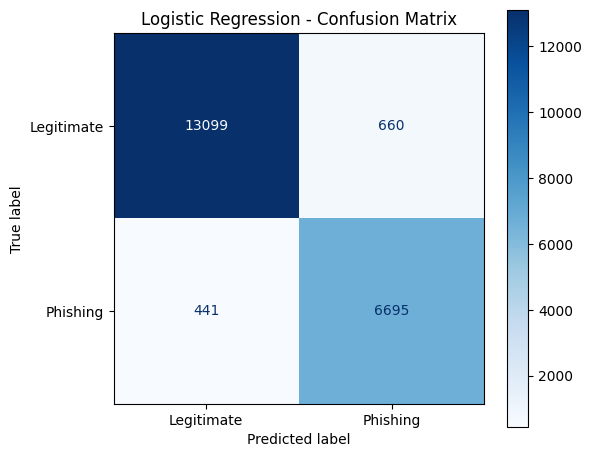

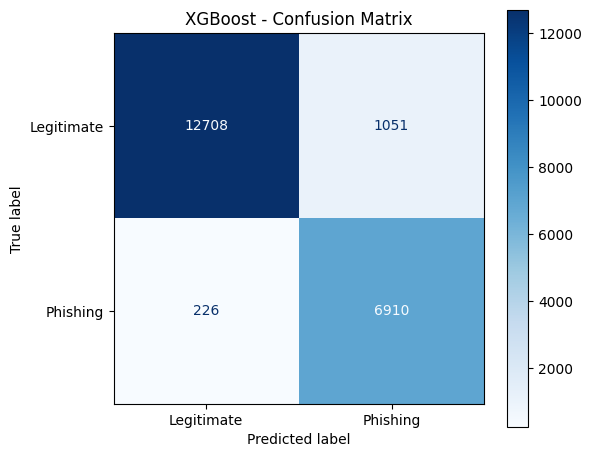

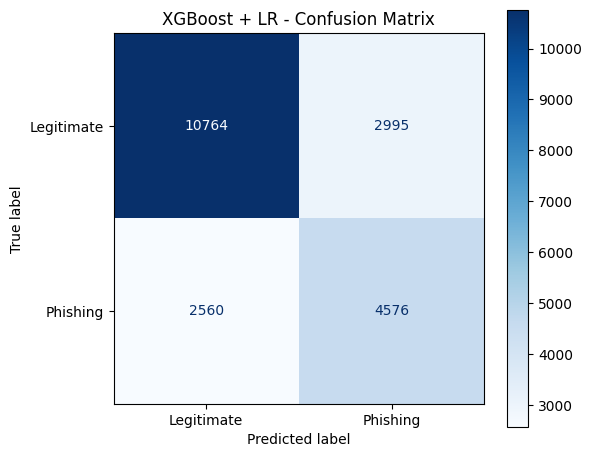

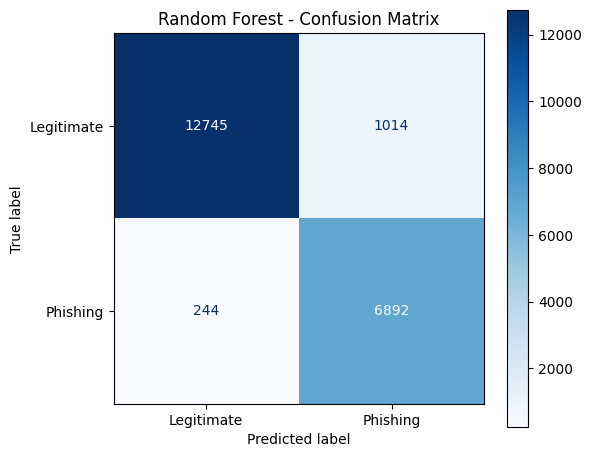

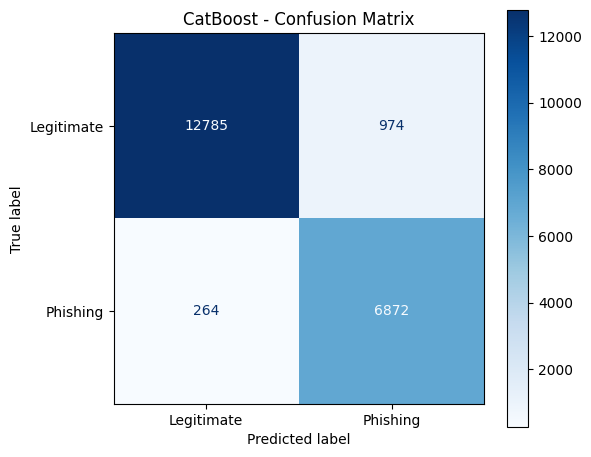

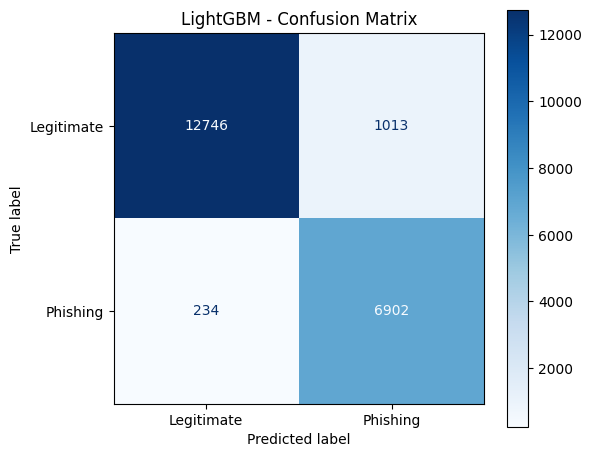

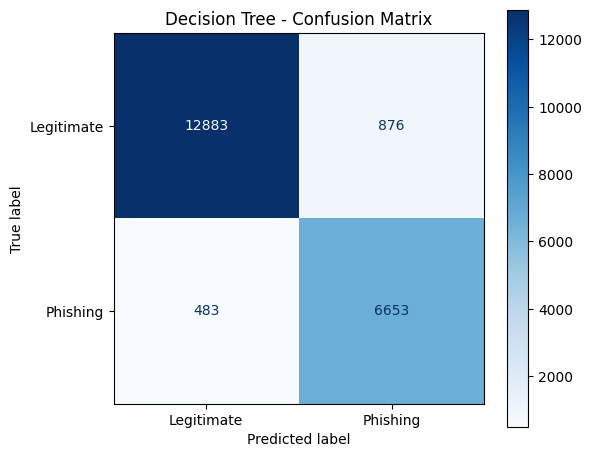

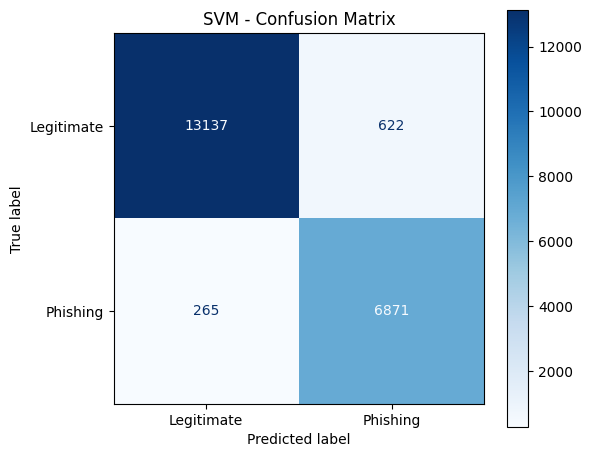

In [10]:
model_paths = {
    "Logistic Regression": lr_path,
    "XGBoost": tuned_xgb_path,
    "XGBoost + LR": xgb_path,
    "Random Forest": rf_path,
    "CatBoost": cat_path,
    "LightGBM": lgbm_path,
    "Decision Tree": dt_path,
    "SVM": svm_path
}

models = {
    "Logistic Regression": final_lr,
    "XGBoost": final_xgb,
    "XGBoost + LR": final_booster,
    "Random Forest": random_forest,
    "CatBoost": cat_model,
    "LightGBM": lgbm_model,
    "Decision Tree": decision_tree,
    "SVM": svm
}

results = []
roc_data = {}
pr_data = {}
predictions = {}

dtest = xgb.DMatrix(x_test)

for name, model in models.items():

    start = time.perf_counter()

    if isinstance(model, xgb.Booster):
        dtest = xgb.DMatrix(x_test)
        y_prob = model.predict(dtest)
        y_pred = (y_prob >= chosen_threshold).astype(int)

    else:
        y_pred = model.predict(x_test)
        y_prob = model.predict_proba(x_test)[:, 1]

    y_pred = y_pred.reshape(-1)

    predictions[name] = {"y_pred": y_pred, "y_prob": y_prob}

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    specificity = tn / (tn + fp) if (tn + fp) else 0
    auc_score = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    model_size_kb = model_paths[name].stat().st_size / 1024

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Specificity": specificity,
        "ROC-AUC": auc_score,
        "PR-AUC": pr_auc
    })

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    roc_data[name] = {
        "fpr": fpr,
        "tpr": tpr,
        "auc": auc_score
    }

    precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob)

    pr_data[name] = {
        "precision": precision_curve,
        "recall": recall_curve,
        "ap": pr_auc
    }

    final_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate", "Phishing"]
    )

    fig, ax = plt.subplots(figsize=(6, 5))
    final_cm.plot(ax=ax, cmap="Blues", values_format="d")
    ax.set_title(f"{name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

## Results Summary

Models ranked by F1-score.

In [11]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(by="F1-score", ascending=False).reset_index(drop=True)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-score,Specificity,ROC-AUC,PR-AUC
0,SVM,0.9575,0.9170,0.9629,0.9394,0.9548,0.9840,0.9646
1,Logistic Regression,0.9473,0.9103,0.9382,0.9240,0.9520,0.9887,0.9832
2,CatBoost,0.9408,0.8759,0.9630,0.9174,0.9292,0.9849,0.9656
3,LightGBM,0.9403,0.8720,0.9672,0.9171,0.9264,0.9904,0.9839
4,Random Forest,0.9398,0.8717,0.9658,0.9164,0.9263,0.9911,0.9859
5,XGBoost,0.9389,0.8680,0.9683,0.9154,0.9236,0.9873,0.9730
6,Decision Tree,0.9350,0.8836,0.9323,0.9073,0.9363,0.9738,0.9390
7,XGBoost + LR,0.7341,0.6044,0.6413,0.6223,0.7823,0.8083,0.5562


## ROC Curves

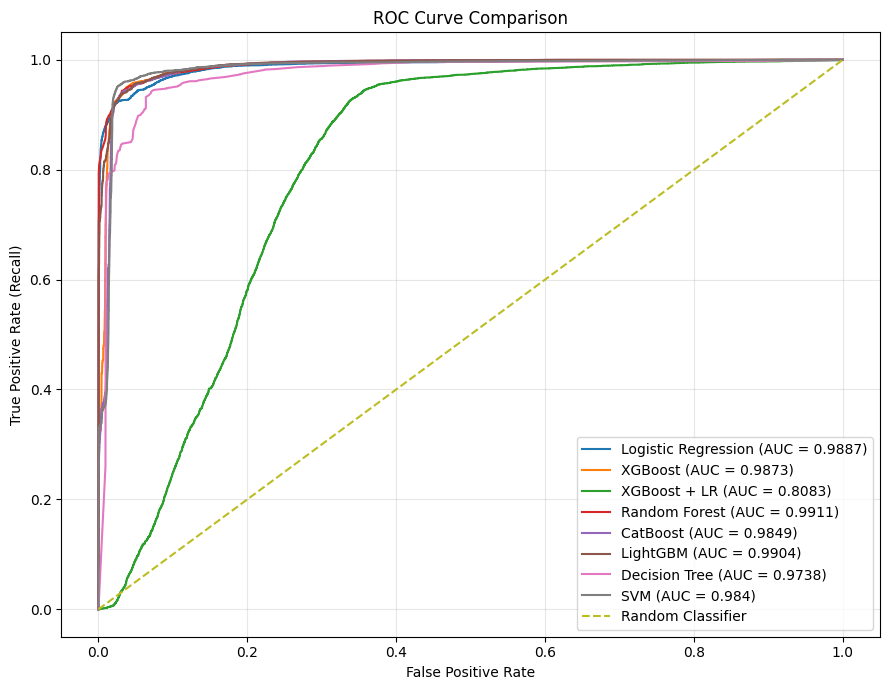

In [12]:
plt.figure(figsize=(9, 7))

for name, data in roc_data.items():
    plt.plot(data["fpr"],data["tpr"],label=f'{name} (AUC = {round(data["auc"],4)})')

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Precision-Recall Curves

More informative than ROC for phishing detection because the classes are imbalanced. The dashed line is the random baseline (the phishing rate).

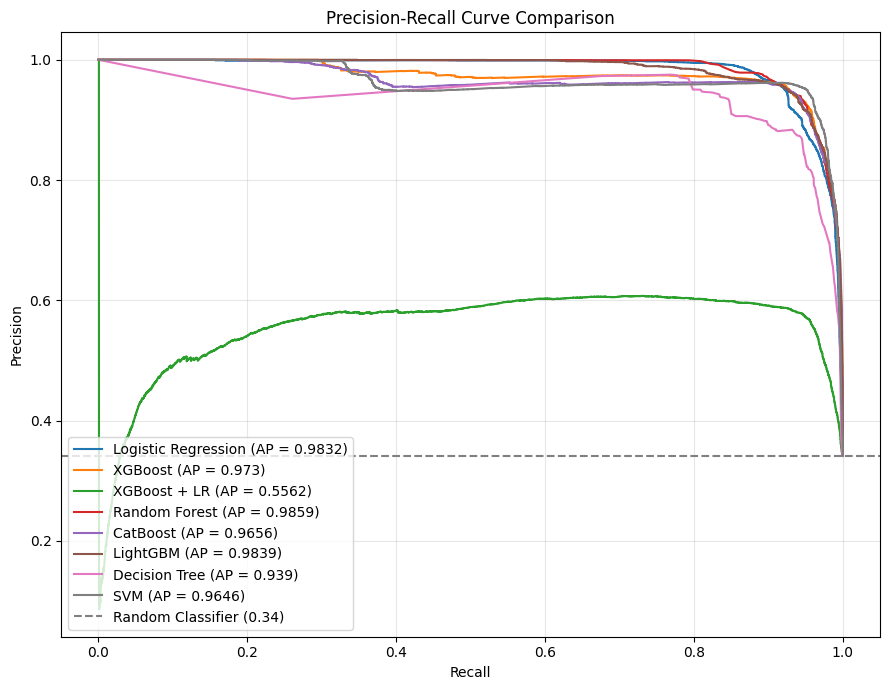

In [13]:
plt.figure(figsize=(9, 7))

for name, data in pr_data.items():
    plt.plot(data["recall"], data["precision"], label=f'{name} (AP = {round(data["ap"],4)})')

baseline = y_test.mean()
plt.axhline(baseline, linestyle="--", color="gray", label=f"Random Classifier ({baseline:.2f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Classification Reports

Per-class precision, recall and F1-score for each model.

In [14]:
for name in results_df["Model"]:
    print(name)
    print(classification_report(y_test,predictions[name]["y_pred"],target_names=LABEL_NAMES,digits=3,zero_division=0),'\n')

SVM
              precision    recall  f1-score   support

  Legitimate      0.980     0.955     0.967     13759
    Phishing      0.917     0.963     0.939      7136

    accuracy                          0.958     20895
   macro avg      0.949     0.959     0.953     20895
weighted avg      0.959     0.958     0.958     20895
 

Logistic Regression
              precision    recall  f1-score   support

  Legitimate      0.967     0.952     0.960     13759
    Phishing      0.910     0.938     0.924      7136

    accuracy                          0.947     20895
   macro avg      0.939     0.945     0.942     20895
weighted avg      0.948     0.947     0.947     20895
 

CatBoost
              precision    recall  f1-score   support

  Legitimate      0.980     0.929     0.954     13759
    Phishing      0.876     0.963     0.917      7136

    accuracy                          0.941     20895
   macro avg      0.928     0.946     0.936     20895
weighted avg      0.944     0.941    

## Feature Importance (Top Model)

Features are PCA components, not the original URL features. Permutation importance (drop in F1-score when a feature is shuffled) is used for scikit-learn style models, and gain for the XGBoost booster.

,Feature,Importance
0,PC01,0.2548
1,PC03,0.1910
2,PC02,0.0765
3,PC04,0.0553
4,PC19,0.0552
5,PC05,0.0437
6,PC18,0.0324
7,PC08,0.0315
8,PC14,0.0299
9,PC09,0.0275


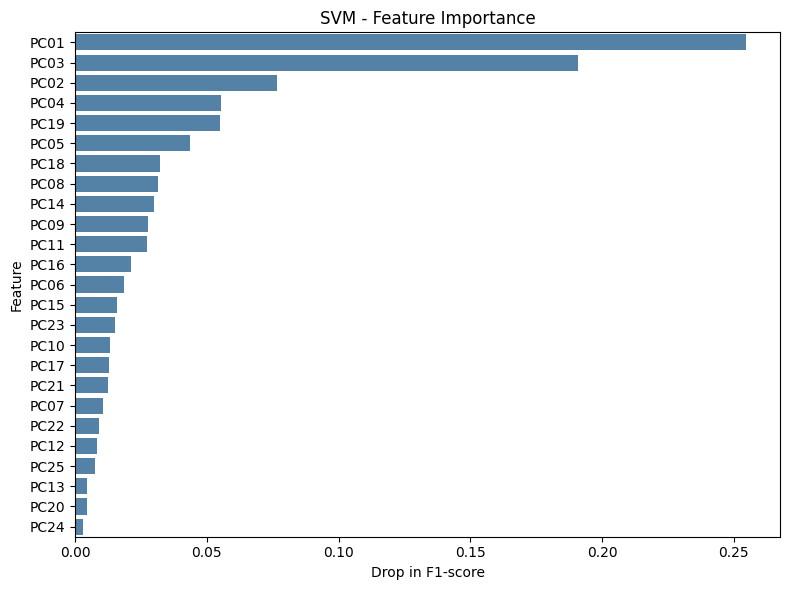

In [15]:
top_model_name = results_df.iloc[0]["Model"]
top_model = models[top_model_name]

if isinstance(top_model, xgb.Booster):
    gain = top_model.get_score(importance_type="gain")
    importance_df = pd.DataFrame({
        "Feature": list(gain.keys()),
        "Importance": list(gain.values())
    })
    x_label = "Mean gain"

else:
    perm = permutation_importance(
        top_model, x_test, y_test,
        scoring="f1", n_repeats=5, random_state=RANDOM_STATE
    )
    importance_df = pd.DataFrame({
        "Feature": x_test.columns,
        "Importance": perm.importances_mean
    })
    x_label = "Drop in F1-score"

importance_df = importance_df.sort_values("Importance", ascending=False).reset_index(drop=True)

display(importance_df.round(4))

plt.figure(figsize=(8, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature", color="steelblue")
plt.xlabel(x_label)
plt.title(f"{top_model_name} - Feature Importance")
plt.tight_layout()
plt.show()

## Best Model

Selects the model with the highest F1-score and saves it to `models/best_model/` (XGBoost booster as native JSON, every other model with Joblib). The saved file is reloaded and its predictions are checked against the original. Because the best model is chosen on the test set, treat its score as the final comparison result.

In [16]:
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

print("Best model:", best_model_name)
print("Best F1-score:", results_df.iloc[0]["F1-score"])

BEST_DIR = MODEL_DIR / "best_model"
BEST_DIR.mkdir(parents=True, exist_ok=True)

if isinstance(best_model, xgb.Booster):
    best_model_path = BEST_DIR / "best_model.json"
    best_model.save_model(best_model_path)

    reloaded_model = xgb.Booster()
    reloaded_model.load_model(best_model_path)

    original_prob = best_model.predict(dtest)
    reloaded_prob = reloaded_model.predict(dtest)
    best_threshold = chosen_threshold

else:
    best_model_path = BEST_DIR / "best_model.joblib"
    joblib.dump(best_model, best_model_path)

    reloaded_model = joblib.load(best_model_path)

    original_prob = best_model.predict_proba(x_test)[:, 1]
    reloaded_prob = reloaded_model.predict_proba(x_test)[:, 1]
    best_threshold = 0.5

if not np.allclose(original_prob, reloaded_prob):
    raise ValueError("Reloaded model predictions differ from the original model.")

best_info = {
    "model_name": best_model_name,
    "model_file": best_model_path.name,
    "threshold": best_threshold,
    "features": list(x_train.columns),
    "metrics": {key: float(value) for key, value in results_df.iloc[0].drop("Model").items()},
    "sklearn_version": sklearn.__version__,
    "xgboost_version": xgb.__version__
}

with open(BEST_DIR / "best_model_info.json", "w") as f:
    json.dump(best_info, f, indent=4)

print("Saved model :", best_model_path.resolve())
print("Saved info  :", (BEST_DIR / "best_model_info.json").resolve())
print("Reload check: passed")

Best model: SVM
Best F1-score: 0.9393670107321075
Saved model : C:\Users\LENOVO\OneDrive\Desktop\new\PhishGuard-AI\models\best_model\best_model.joblib
Saved info  : C:\Users\LENOVO\OneDrive\Desktop\new\PhishGuard-AI\models\best_model\best_model_info.json
Reload check: passed
